# Lab 5 — Design a pipe network with the Hardy–Cross method
### ENVE 3120 • Flow guesses, loop corrections, and defensible diameter choices

**System:** two reservoirs, nine pipes, six demand junctions. **Main question:** how do you choose a starting design and adjust flows until both mass and energy balance?

You will audit the demand data, choose a continuity-preserving initial flow, select preliminary diameters near a 1 m/s target, perform and inspect loop corrections, check the result using an independent equation solver, compare designs, and draw HGL/EGL profiles.

![Redrawn nine-pipe system and three independent constraints](assets/lab5_network.svg)

**Route:** source audit → continuity → diameter selection → hand correction → iterative solution → independent check → grade lines → design experiments → report and export.


## Before you begin: operating the notebook

This is a **computational experiment**: you will vary a model, predict the response, run it, check the equations, and interpret the result. Computed values are not field measurements.

1. Open this notebook in Binder or JupyterLab. Click a cell, then press **Shift + Enter** to run it and move forward. Text cells explain the next calculation. Code cells execute it.
2. On your first visit, use **Kernel → Restart Kernel and Run All Cells**. This builds a complete working example, including figures and downloadable tables. Then return to the experiment cells and change one input at a time.
3. A busy kernel / `[*]` means calculation is running. Read the timestamped messages under the cell. Do not repeatedly click Compute. Most calculations should take seconds after the environment starts.
4. Run cells from top to bottom after editing earlier inputs. A variable from an old run can otherwise survive in memory. A clean restart is your final reproducibility check.
5. Save the notebook and **download it and the results ZIP before closing Binder**. Binder storage is temporary. Saving within Binder does not save a copy to your laptop or push anything to GitHub.

**What to edit:** cells labelled **YOUR INPUTS**, the interactive controls, and the response boxes. The default case is fully runnable; there are no unfinished code placeholders. Keep units in every hand calculation. In code, flows are m³/s, lengths and roughness are m, and diameters are m unless the field explicitly says mm.

**Logging:** every computational stage reports its purpose. Iterative solvers report residuals: the mismatch left in the governing equations. A plausible-looking plot alone is not proof of convergence. A traceback stops a failed calculation; correct the inputs and rerun rather than using stale output. Full logs are also stored in `outputs/`. Each export includes this lab’s session log, which may contain several scenarios; `inputs.json` always identifies the exact exported case.


## 1. Set up the experiment
The notebook can be run independently of Lab 4. It uses the same local helper module but creates its own configuration, log, and output files.


In [1]:
%matplotlib inline
from pathlib import Path
import os, sys, copy, json, platform
# Find the repository support module when launched at the root or one subfolder below.
candidates = [Path.cwd(), Path.cwd().parent]
LAB_DIR = next((p.resolve() for p in candidates if (p / 'hydraulics.py').exists()), None)
if LAB_DIR is None:
    raise FileNotFoundError('Open this notebook with the accompanying hydraulics.py, lab_widgets.py, and assets folder.')
os.chdir(LAB_DIR)
if str(LAB_DIR) not in sys.path:
    sys.path.insert(0, str(LAB_DIR))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Math
from hydraulics import *
pd.set_option('display.max_columns', 15)
pd.set_option('display.precision', 5)
log = start_log('lab5')
log.info('Python %s | NumPy %s | support files found; results saved in outputs/', platform.python_version(), np.__version__)
display(HTML("""<style>
.jp-RenderedHTMLCommon h1,.jp-RenderedHTMLCommon h2 {color:#17345b;}
.jp-RenderedHTMLCommon table {font-size:1em;}
.jp-RenderedHTMLCommon blockquote {border-left:5px solid #2c70b7;padding:8px 16px;background:#eef4fc;color:#17345b;}
</style>"""))
log.info('Setup complete. INFO reports progress; WARNING identifies an assumption or a result needing interpretation.')


09:38:25 | INFO    | Session started. SI units; Darcy friction factor; logs also saved to outputs/lab5.log.


09:38:25 | INFO    | Python 3.12.3 | NumPy 2.2.6 | support files found; results saved in outputs/


09:38:25 | INFO    | Setup complete. INFO reports progress; WARNING identifies an assumption or a result needing interpretation.


## 2. Audit the manual: demand is not a single unambiguous number

The network figure gives reservoir heads **160 m and 180 m**; junction elevations A/B = 100 m, C/D = 94 m, E/F = 88 m. The pipe-length table and all six demand entries are transcribed directly.

The demand table sums to **78.10 L/s**. The population statement implies

$$15000\ \text{people}\times300\ \frac{\mathrm{L}}{\text{person day}}
\div86400\ \frac{\mathrm{s}}{\mathrm{day}}=52.0833\ \mathrm{L/s}.$$

These are different: the tabulated case is 1.49952 times the population average. That ratio might resemble a peak multiplier, but the manual does **not** identify it as one. Do not silently label it a peak-demand factor.

We use the **tabulated demand as the default design case** and provide a second case that scales all six node demands proportionally to the population average. State which you use. The 30 city blocks are context; their individual demand allocation is not supplied.

The roughness is **0.015 cm = 0.00015 m = 0.15 mm**. Confusing cm and m changes the hydraulics substantially. The manual permits friction losses to dominate, so the baseline omits local losses. Water has $\nu=1.004\times10^{-6}$ m²/s as an explicit near-20 °C assumption.


In [2]:
step(log, 2, 'Compare the two demand interpretations and transcribe the source data')
# YOUR INPUT: 'table' or 'population'. Start with 'table'.
DEMAND_MODE = 'table'
config = lab5_config(DEMAND_MODE)
display(config['pipes'][['start','end','L_m','eps_m']])
display(pd.DataFrame({'elevation_m':config['elevations'],
                      'demand_L_s':{n:q*1000 for n,q in config['demand'].items()}}))
population_average_L_s = 15000*300/86400
table_total_L_s = sum(lab5_config('table')['demand'].values())*1000
log.warning('Manual table = %.5f L/s; population average = %.5f L/s; ratio = %.5f. Both are retained as separate cases.',
            table_total_L_s, population_average_L_s, table_total_L_s/population_average_L_s)
log.info('Selected demand mode: %s. Roughness conversion: 0.015 cm = 0.15 mm = 0.00015 m.', DEMAND_MODE)


09:38:25 | INFO    | STEP 2 | Compare the two demand interpretations and transcribe the source data


,start,end,L_m,eps_m
pipe,,,,
AR1,A,R1,2000,0.00015
AB,A,B,1200,0.00015
BR2,B,R2,1500,0.00015
AC,A,C,300,0.00015
CD,C,D,1200,0.00015
DB,D,B,300,0.00015
CE,C,E,300,0.00015
EF,E,F,1200,0.00015
FD,F,D,300,0.00015


,elevation_m,demand_L_s
A,100,7.81
B,100,7.81
C,94,16.27
D,94,16.27
E,88,14.97
F,88,14.97


09:38:25 | WARNING | Manual table = 78.10000 L/s; population average = 52.08333 L/s; ratio = 1.49952. Both are retained as separate cases.


09:38:25 | INFO    | Selected demand mode: table. Roughness conversion: 0.015 cm = 0.15 mm = 0.00015 m.


## 3. Choose reference directions and write continuity first

Pipe names are identifiers. For example, **BR2 is referenced B → R2**. It is entirely reasonable for its final signed Q to be negative when R2 supplies the town. Speeds and friction factors use $|Q|$.

For this notebook, $B_{ij}=+1$ when pipe j leaves junction i, $-1$ when it enters, and 0 otherwise. With a positive withdrawal $d_i$, continuity is

$$B\mathbf Q+\mathbf d=0.$$

At A, for example, $Q_{AR1}+Q_{AB}+Q_{AC}+d_A=0$. At B, $Q_{BR2}-Q_{AB}-Q_{DB}+d_B=0$. Check those equations against the arrows before using the matrix.

An initial flow need not satisfy energy, but **it must satisfy continuity** for Hardy–Cross. The code creates one balanced seed by linear algebra, then adds small closed-loop and reservoir-transfer flows. These additions preserve every junction’s balance. They are starting guesses, not measured or final flows.


09:38:25 | INFO    | STEP 3 | Construct and verify a continuity-preserving initial flow


pipe,AR1,AB,BR2,AC,CD,DB,CE,EF,FD
A,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
B,0.0,-1.0,1.0,0.0,0.0,-1.0,0.0,0.0,0.0
C,0.0,0.0,0.0,-1.0,1.0,0.0,1.0,0.0,0.0
D,0.0,0.0,0.0,0.0,-1.0,1.0,0.0,0.0,-1.0
E,0.0,0.0,0.0,0.0,0.0,0.0,-1.0,1.0,0.0
F,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-1.0,1.0


,initial_Q_L_s
pipe,
AR1,-29.05
AB,-5.00
BR2,-49.05
AC,26.24
CD,-2.00
DB,-36.24
CE,11.97
EF,-3.00
FD,-17.97


,outflow_plus_demand_m3_s
A,1.56125e-17
B,2.25514e-17
C,4.85723e-17
D,2.42861e-17
E,1.73472e-17
F,6.93889e-18


09:38:25 | INFO    | Initial maximum continuity residual = 4.857e-17 m3/s. Energy has not yet been balanced.


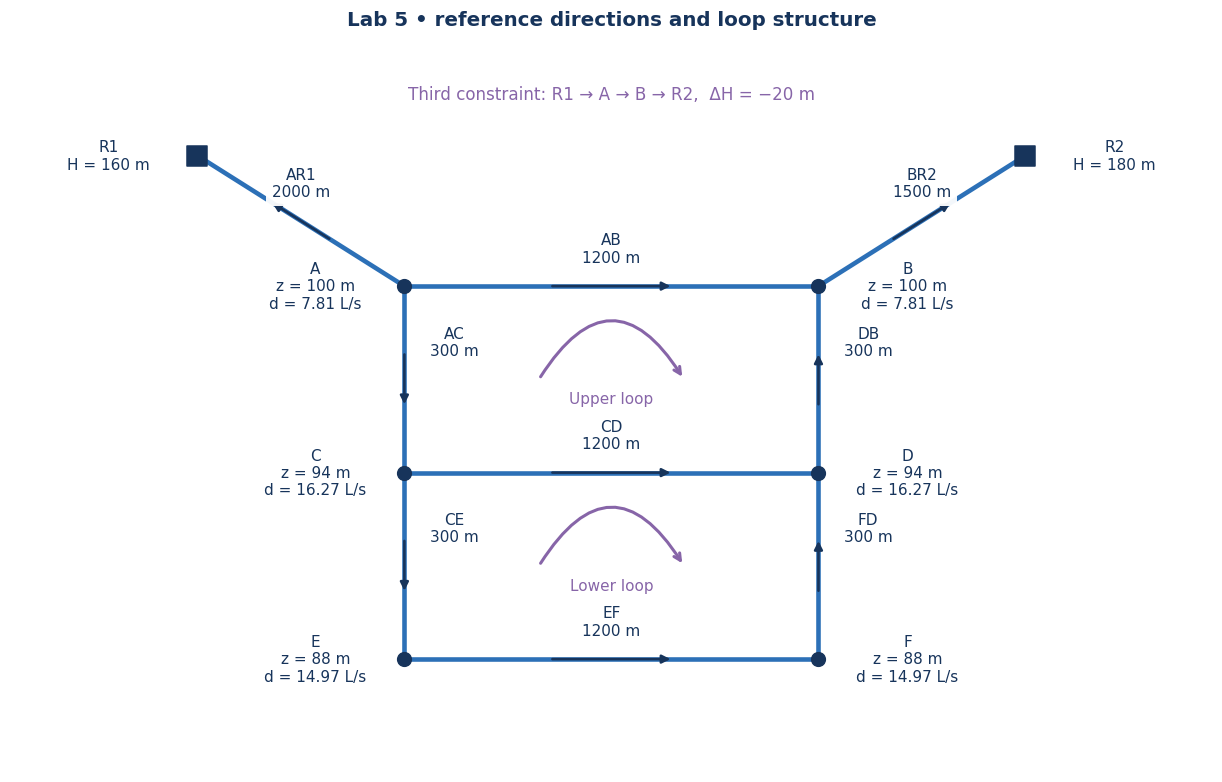

In [3]:
step(log, 3, 'Construct and verify a continuity-preserving initial flow')
B = incidence5(config)
d = np.array([config['demand'][n] for n in NODES5])
# YOUR INPUT: circulation / reservoir-transfer guesses in L/s.
# These three numbers preserve continuity by construction.
initial_adjustments_L_s = np.array([5.0, 3.0, -10.0])
q0 = initial5(config) + CYCLES.T @ (initial_adjustments_L_s/1000)
validate5(config, q0)
display(pd.DataFrame(B,index=NODES5,columns=config['pipes'].index))
display(pd.DataFrame({'initial_Q_L_s':q0*1000},index=config['pipes'].index))
display(pd.DataFrame({'outflow_plus_demand_m3_s':B@q0+d},index=NODES5))
log.info('Initial maximum continuity residual = %.3e m3/s. Energy has not yet been balanced.', max(abs(B@q0+d)))
fig = network_plot5(cfg=config, loops=True); display(fig); plt.close(fig)


## 4. YOUR DESIGN — choose preliminary diameters

For a target speed $V_t\approx1$ m/s,

$$D_{\rm trial}=\sqrt{\frac{4|Q_{\rm guess}|}{\pi V_t}}.$$

This estimates a starting diameter from the **guessed** flow. Choose a practical diameter at or above that value, then solve the network and recheck actual speed. The notebook offers an **illustrative teaching catalog**; it is not a statement of locally available sizes or actual internal diameters. The smallest catalog size is used if the seed flow is zero or very small—zero seed flow does not justify deleting a pipe.

You may override any diameter in the next cell. A larger pipe reduces friction resistance but can redistribute flow throughout the network. The manual supplies no cost function, maximum pressure, or minimum service pressure, so there is no uniquely defined “optimal” design. Use the adjustable screening criteria later as disclosed teaching choices.


In [4]:
step(log, 4, 'Select preliminary sizes and allow explicit design edits')
TARGET_SPEED_M_S = 1.0
config, sizing = size5(config, q0, target=TARGET_SPEED_M_S)
# YOUR INPUT: optional overrides in mm. Example: {'AB':150, 'CD':150}
DIAMETER_OVERRIDES_MM = {}
for pipe, D_mm in DIAMETER_OVERRIDES_MM.items():
    if pipe not in config['pipes'].index: raise ValueError(f'Unknown pipe {pipe}')
    config['pipes'].loc[pipe,'D_m'] = D_mm/1000
validate5(config, q0)
display(sizing.round(4))
display((config['pipes'].D_m*1000).rename('actual_design_D_mm').to_frame())
log.info('Preliminary diameter selection complete. Final velocities can differ from 1 m/s after the network is balanced.')


09:38:25 | INFO    | STEP 4 | Select preliminary sizes and allow explicit design edits


,Q_seed_L_s,D_at_target_mm,D_selected_mm,seed_speed_m_s
pipe,,,,
AR1,-29.05,192.3216,200.0,0.9247
AB,-5.00,79.7885,100.0,0.6366
BR2,-49.05,249.9048,250.0,0.9992
AC,26.24,182.7835,200.0,0.8352
CD,-2.00,50.4627,100.0,0.2546
DB,-36.24,214.8074,250.0,0.7383
CE,11.97,123.4531,125.0,0.9754
EF,-3.00,61.8039,100.0,0.3820
FD,-17.97,151.2617,200.0,0.5720


,actual_design_D_mm
pipe,
AR1,200.0
AB,100.0
BR2,250.0
AC,200.0
CD,100.0
DB,250.0
CE,125.0
EF,100.0
FD,200.0


09:38:25 | INFO    | Preliminary diameter selection complete. Final velocities can differ from 1 m/s after the network is balanced.


## 5. Why two visible loops are not enough

There are two geometric loops, but the two reservoirs have **different prescribed heads**. A third independent energy condition is needed to determine the division of reservoir supply.

| Path | Signed pipe sum | Required head change |
|---|---|---|
| Upper: A → B → D → C → A | $h_{AB}-h_{DB}-h_{CD}-h_{AC}$ | 0 |
| Lower: C → D → F → E → C | $h_{CD}-h_{FD}-h_{EF}-h_{CE}$ | 0 |
| Reservoir path: R1 → A → B → R2 | $-h_{AR1}+h_{AB}+h_{BR2}$ | $160-180=-20$ m |

The reservoir path is often called a **pseudo-loop**: imagine an extra fixed-head connection closing it, but do not add a fictitious physical pipe or its friction. The signed path loss equals the actual reservoir-head difference, not zero.

With nine pipe flows and six independent continuity equations, three independent energy conditions remain. Omitting the reservoir path can produce balanced visible loops while giving the wrong source split.

The rows of `CYCLES` encode these paths. The identity $BC^T=0$ means any correction of the form $C^T\Delta\mathbf q$ preserves all six junction balances.


In [5]:
step(log, 5, 'Check the loop definitions and the reservoir-head constraint')
display(pd.DataFrame(CYCLES,index=LOOP_NAMES,columns=config['pipes'].index))
assert np.linalg.matrix_rank(CYCLES) == 3
assert np.max(abs(B@CYCLES.T)) < 1e-12
display(pd.Series(targets5(config),index=LOOP_NAMES,name='required_signed_head_change_m'))
log.info('Three independent corrections preserve continuity. The reservoir-path target is %.3f m, not zero.', targets5(config)[2])


09:38:25 | INFO    | STEP 5 | Check the loop definitions and the reservoir-head constraint


pipe,AR1,AB,BR2,AC,CD,DB,CE,EF,FD
upper loop A-B-D-C-A,0.0,1.0,0.0,-1.0,-1.0,-1.0,0.0,0.0,0.0
lower loop C-D-F-E-C,0.0,0.0,0.0,0.0,1.0,0.0,-1.0,-1.0,-1.0
reservoir path R1-A-B-R2,-1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


upper loop A-B-D-C-A         0.0
lower loop C-D-F-E-C         0.0
reservoir path R1-A-B-R2   -20.0
Name: required_signed_head_change_m, dtype: float64

09:38:25 | INFO    | Three independent corrections preserve continuity. The reservoir-path target is -20.000 m, not zero.


## 6. One correction by hand: signs, numerator, denominator

This is the loop-balancing idea developed by Cross (1936), extended here to recompute the friction factor during iteration.

Use the signed pipe loss $h_i(Q_i)=r_iQ_i|Q_i|$. For a path with signs $s_i$, define the energy residual

$$F=\sum_i s_i h_i-H_{\rm target}.$$

A correction $\Delta q$ changes pipe i by $s_i\Delta q$. Linearizing gives

$$\boxed{\Delta q=-\frac{F}{\sum_i s_i^2\,dh_i/dQ_i}}.$$

For **fixed f**, $dh_i/dQ_i=2r_i|Q_i|$, giving the familiar Hardy–Cross denominator. For **fixed roughness**, f changes with Reynolds number. Our solver recomputes f and uses a symmetric numerical derivative of the full loss law, including that dependence. It is a sequential loop-correction method with a more accurate local slope. Corrections are damped if a full step would worsen that path’s residual.

The friction model is $64/\mathrm{Re}$ below Re = 2000 and iterative Colebrook above 4000. Between them, it uses an explicitly chosen linear blend; transitional flow is uncertain and is flagged when present in a final result. At Q = 0, loss is exactly zero; the low-flow derivative stays finite through the laminar law.

**Hand exercise:** for the upper loop, fill a table with Q, sign, Re, f, signed head loss, and signed loop contribution. Sum the numerator, form the denominator, calculate $\Delta q$, and update the four affected pipes. Afterward recheck A, B, C, and D continuity.


In [6]:
step(log, 6, 'Expose the first upper-loop correction')
first_table, first_residual, first_delta = first_correction5(config, q0, loop=0)
display(first_table)
log.info('First-loop residual F = %+.8f m; full local Newton correction = %+.8f L/s.', first_residual, first_delta*1000)
q_after_one = q0 + CYCLES[0]*first_delta
assert max(abs(B@q_after_one+d)) < 1e-9
log.info('Applying that one correction preserves continuity: %.2e m3/s. Other loop energies are not yet solved.', max(abs(B@q_after_one+d)))
# Compare the familiar frozen-f denominator with the variable-f denominator.
h0 = losses5(config, q0)
mask = CYCLES[0] != 0
frozen_terms = np.divide(2*np.abs(h0[mask]), np.abs(q0[mask]),
                         out=np.zeros(np.sum(mask)), where=np.abs(q0[mask])>1e-12)
frozen_denominator = np.sum(frozen_terms)
frozen_delta = -first_residual/frozen_denominator
log.info('For comparison, freezing f gives a first correction of %+.8f L/s.', frozen_delta*1000)


09:38:25 | INFO    | STEP 6 | Expose the first upper-loop correction


,Q_L_s,loop_sign,f_D,signed_h_m,loop_contribution_m,derivative_s_m2
pipe,,,,,,
AB,-5.00,1.0,0.02469,-6.11962,-6.11962,2326.17609
AC,26.24,-1.0,0.02029,1.08194,-1.08194,79.10642
CD,-2.00,-1.0,0.02777,-1.10145,1.10145,1014.20500
DB,-36.24,-1.0,0.01945,-0.64848,0.64848,34.22725


09:38:25 | INFO    | First-loop residual F = -5.45163463 m; full local Newton correction = +1.57848432 L/s.


09:38:25 | INFO    | Applying that one correction preserves continuity: 5.20e-17 m3/s. Other loop energies are not yet solved.


09:38:25 | INFO    | For comparison, freezing f gives a first correction of +1.48645064 L/s.


**Your hand-work explanation:**

Show at least one pipe’s calculation, explain the sign of the first correction, and explain why the shared pipe CD must be updated immediately before the lower-loop calculation. State why a nearly zero change in Q alone is not a sufficient stopping test.


## 7. Run Hardy–Cross: watch the equations converge

Each **sweep** visits the upper loop, lower loop, and reservoir path in that order, using the most recently updated flows. The log reports the first five sweeps, every tenth sweep, and convergence. The full sweep history is saved, including all three energy residuals and the maximum continuity residual.

The stopping condition is a maximum path-energy residual below $10^{-8}$ m. A hard iteration limit prevents an endless run. After convergence, heads are reconstructed from all nine pipe equations and checked for consistency. A run that fails mass or energy checks is rejected.

The logging frequency avoids thousands of lines while keeping progress visible. You can inspect every saved sweep in `solution['history']`.


09:38:25 | INFO    | STEP 7 | Balance all three paths with sequential Hardy-Cross corrections


09:38:25 | INFO    | Sweep 001 | max energy residual 2.907e+01 m | largest correction 8.161e+00 L/s | mass 5.20e-17 m3/s


09:38:25 | INFO    | Sweep 002 | max energy residual 9.284e+00 m | largest correction 4.386e+00 L/s | mass 4.86e-17 m3/s


09:38:25 | INFO    | Sweep 003 | max energy residual 6.276e+00 m | largest correction 1.465e+00 L/s | mass 4.86e-17 m3/s


09:38:25 | INFO    | Sweep 004 | max energy residual 3.995e+00 m | largest correction 9.530e-01 L/s | mass 4.86e-17 m3/s


...

09:38:26 | INFO    | R2: supplies 61.7697 L/s


,Q_m3_s,Q_L_s,direction,D_mm,V_m_s,Re,f_D,loss_m
pipe,,,,,,,,
AR1,-0.01633,-16.33034,R1 -> A,200.0,0.51981,103547.95807,0.02121,2.92165
AB,-0.00767,-7.66753,B -> A,100.0,0.97626,97237.09813,0.02379,13.86514
BR2,-0.06177,-61.76966,R2 -> B,250.0,1.25836,313336.96599,0.01870,9.05651
AC,0.01619,16.18787,A -> C,200.0,0.51528,102644.59058,0.02123,0.43104
CD,-0.00749,-7.49139,D -> C,100.0,0.95383,95003.29049,0.02383,13.25879
DB,-0.04629,-46.29213,B -> D,250.0,0.94306,234824.59349,0.01907,1.03738
CE,0.00741,7.40926,C -> E,125.0,0.60376,75169.37658,0.02344,1.04529
EF,-0.00756,-7.56074,F -> E,100.0,0.96266,95882.86079,0.02381,13.49594
FD,-0.02253,-22.53074,D -> F,200.0,0.71718,142863.72116,0.02055,0.80814


,z_m,HGL_m,demand_m3_s,pressure_head_m,gauge_pressure_kPa
A,100,157.07835,0.00781,57.07835,558.93073
B,100,170.94349,0.00781,70.94349,694.70289
C,94,156.64731,0.01627,62.64731,613.46387
D,94,169.90610,0.01627,75.90610,743.29851
E,88,155.60202,0.01497,67.60202,661.98207
F,88,169.09796,0.01497,81.09796,794.13897


,sweep,upper_m,lower_m,reservoir_path_m,max_energy_m,max_dQ_m3_s,mass_m3_s
0,1,-29.06783,-0.01040,-13.94472,29.06783,0.00816,5.20417e-17
1,2,-9.28446,-0.04796,-0.27846,9.28446,0.00439,4.85723e-17
2,3,-6.27635,-0.00689,-0.32896,6.27635,0.00147,4.85723e-17
3,4,-3.99541,-0.00299,-0.12069,3.99541,0.00095,4.85723e-17
4,5,-2.57911,-0.00119,-0.04958,2.57911,0.00059,4.51028e-17
5,6,-1.67322,-0.00049,-0.02061,1.67322,0.00038,4.85723e-17
6,7,-1.08900,-0.00020,-0.00866,1.08900,0.00024,4.85723e-17
7,8,-0.71019,-0.00009,-0.00366,0.71019,0.00016,4.85723e-17


,sweep,upper_m,lower_m,reservoir_path_m,max_energy_m,max_dQ_m3_s,mass_m3_s
46,47,-4.67114e-08,2.22045e-15,3.55271e-15,4.67114e-08,1.02273e-11,5.20417e-17
47,48,-3.05735e-08,-2.55351e-15,0.00000e+00,3.05735e-08,6.69399e-12,5.20417e-17
48,49,-2.00110e-08,6.99441e-15,-3.55271e-15,2.00110e-08,4.38135e-12,5.20417e-17
49,50,-1.30976e-08,-1.22125e-15,3.55271e-15,1.30976e-08,2.86768e-12,4.85723e-17
50,51,-8.57261e-09,3.77476e-15,3.55271e-15,8.57261e-09,1.87695e-12,5.20417e-17


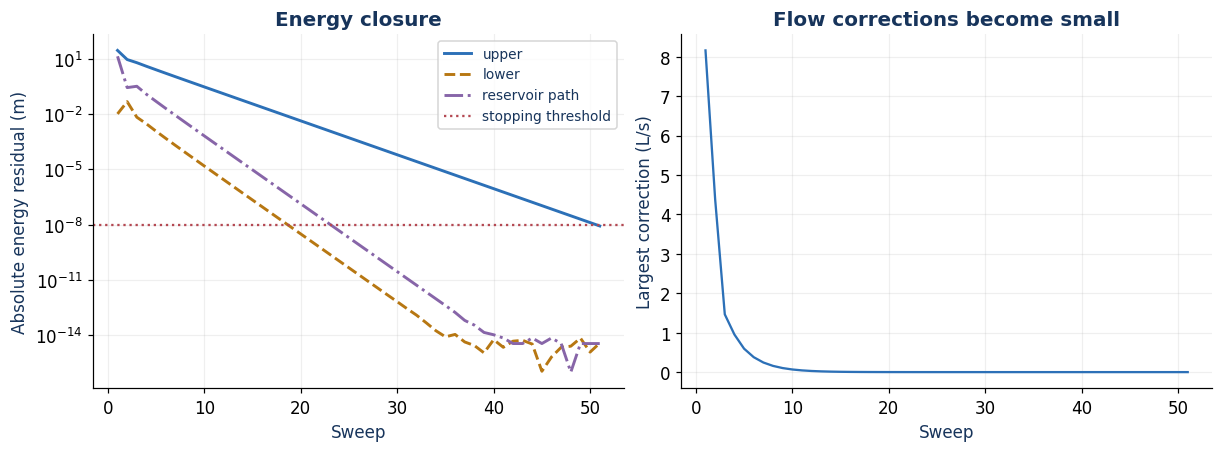

In [7]:
step(log, 7, 'Balance all three paths with sequential Hardy-Cross corrections')
solution = hardy_cross5(config, q0=q0, log=log)
display(solution['pipes'].round(5))
display(solution['nodes'].round(5))
display(solution['history'].head(8))
display(solution['history'].tail(5))
fig = plot_history5(solution); display(fig); plt.close(fig)


## 8. Independent verification: solve all equations at once

The next calculation uses a different numerical route: it solves all nine pipe-energy equations and six node-continuity equations simultaneously for the nine flows and six heads. It uses no loop corrections. Both methods share the same pipe friction law, so agreement checks the network solution but does not independently validate the constitutive law or the source data.

Also verify reservoir supply directly. With our pipe references, $Q_{R1,\rm supply}=-Q_{AR1}$ and $Q_{R2,\rm supply}=-Q_{BR2}$. Their sum must equal the prescribed demand. A negative “supply” means that reservoir receives water, which is allowed in this idealized fixed-head model.


09:38:26 | INFO    | STEP 8 | Cross-check with simultaneous node/pipe equations


,Hardy_Cross_L_s,simultaneous_equations_L_s,difference_L_s
pipe,,,
AR1,-16.33034,-16.33034,-3.01648e-09
AB,-7.66753,-7.66753,-5.39811e-10
BR2,-61.76966,-61.76966,3.01657e-09
AC,16.18787,16.18787,3.55630e-09
CD,-7.49139,-7.49139,1.86864e-09
DB,-46.29213,-46.29213,3.55638e-09
CE,7.40926,7.40926,1.68771e-09
EF,-7.56074,-7.56074,1.68773e-09
FD,-22.53074,-22.53074,1.68775e-09


09:38:26 | INFO    | Independent flow agreement: 3.556e-09 L/s. Supply = 78.100000 L/s; withdrawals = 78.100000 L/s.


,reservoir_supply_L_s
R1,16.33034
R2,61.76966


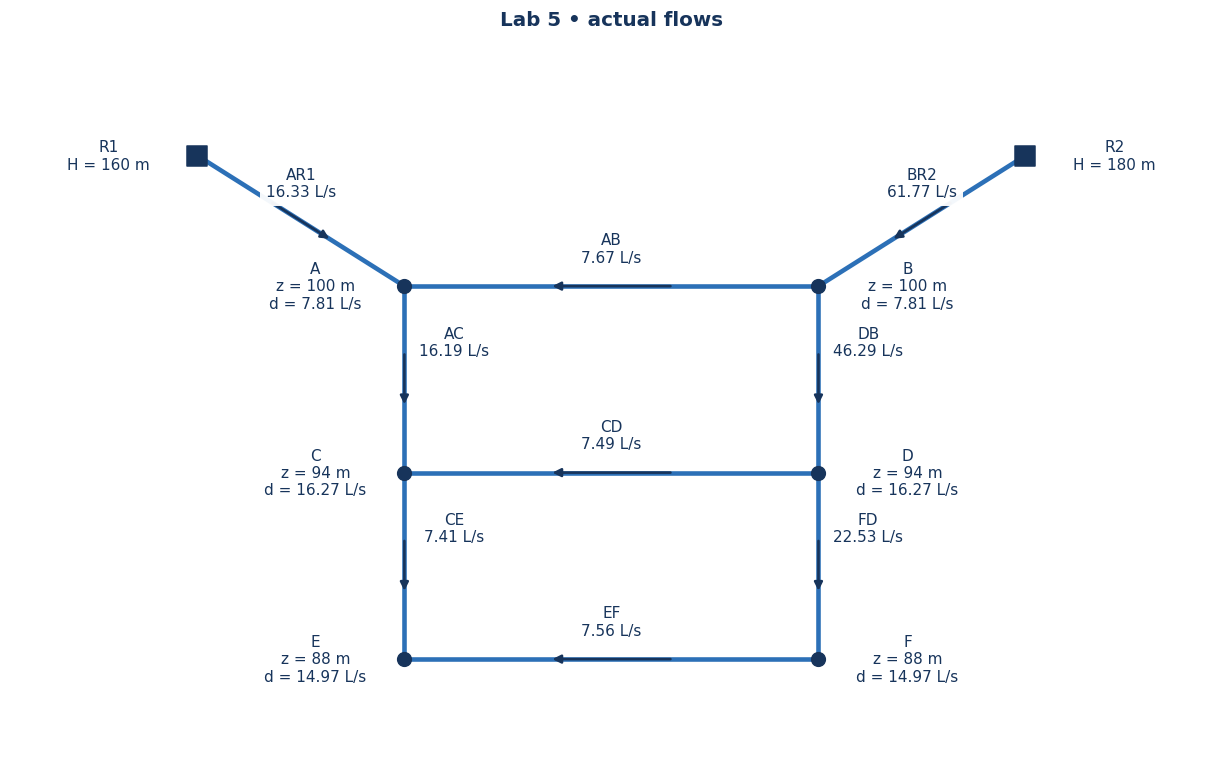

In [8]:
step(log, 8, 'Cross-check with simultaneous node/pipe equations')
reference = independent5(config)  # starts independently; not from the converged Hardy-Cross answer
compare = pd.DataFrame({'Hardy_Cross_L_s':solution['pipes'].Q_L_s,
                        'simultaneous_equations_L_s':reference['pipes'].Q_L_s})
compare['difference_L_s'] = compare.iloc[:,0]-compare.iloc[:,1]
display(compare)
assert np.max(np.abs(compare.difference_L_s)) < 1e-5
supply_total = sum(solution['supplies'].values())
assert abs(supply_total-sum(config['demand'].values())) < 1e-9
log.info('Independent flow agreement: %.3e L/s. Supply = %.6f L/s; withdrawals = %.6f L/s.',
         np.max(np.abs(compare.difference_L_s)), supply_total*1000, sum(config['demand'].values())*1000)
display(pd.Series({n:q*1000 for n,q in solution['supplies'].items()},name='reservoir_supply_L_s').to_frame())
fig = network_plot5(solution); display(fig); plt.close(fig)


## 9. HGL and EGL in a network model

At a junction, $H=z+p_g/(\rho g)$ is the modeled **hydraulic grade**. Along each constant-diameter pipe, HGL decreases in the direction of flow. On the pipe side,

$$\mathrm{EGL}=\mathrm{HGL}+\frac{V^2}{2g}.$$

The nine plots are organized **pipe by pipe in actual flow direction**. This avoids suggesting that a single line follows one unique flow path through a branching network. Water at a junction can leave through several pipes with different velocities.

**Model scope:** consistent with the manual’s friction-dominated assumption and standard distribution-network practice, the nodal equations neglect junction velocity-head differences and local losses. The plotted pipe-side EGL is HGL plus that pipe’s velocity head. Do not connect different pipes’ EGL endpoints and interpret the jump as a computed fitting loss. At a reservoir’s free surface, actual EGL = HGL = its water level; the displayed pipe-side endpoint retains the pipe velocity head because entrance/exit details are omitted by this approximation. For a detailed reservoir transition, use the local-loss treatment illustrated in Lab 4.

Pipe elevation is linearly interpolated between the listed endpoint elevations. The reservoir-end elevation is only a plotting reference at the water level; the manual does not specify connection depth. Pressure reported at A–F uses the supplied node elevations.


09:38:26 | INFO    | STEP 9 | Plot all nine pipe grade profiles and list junction pressures


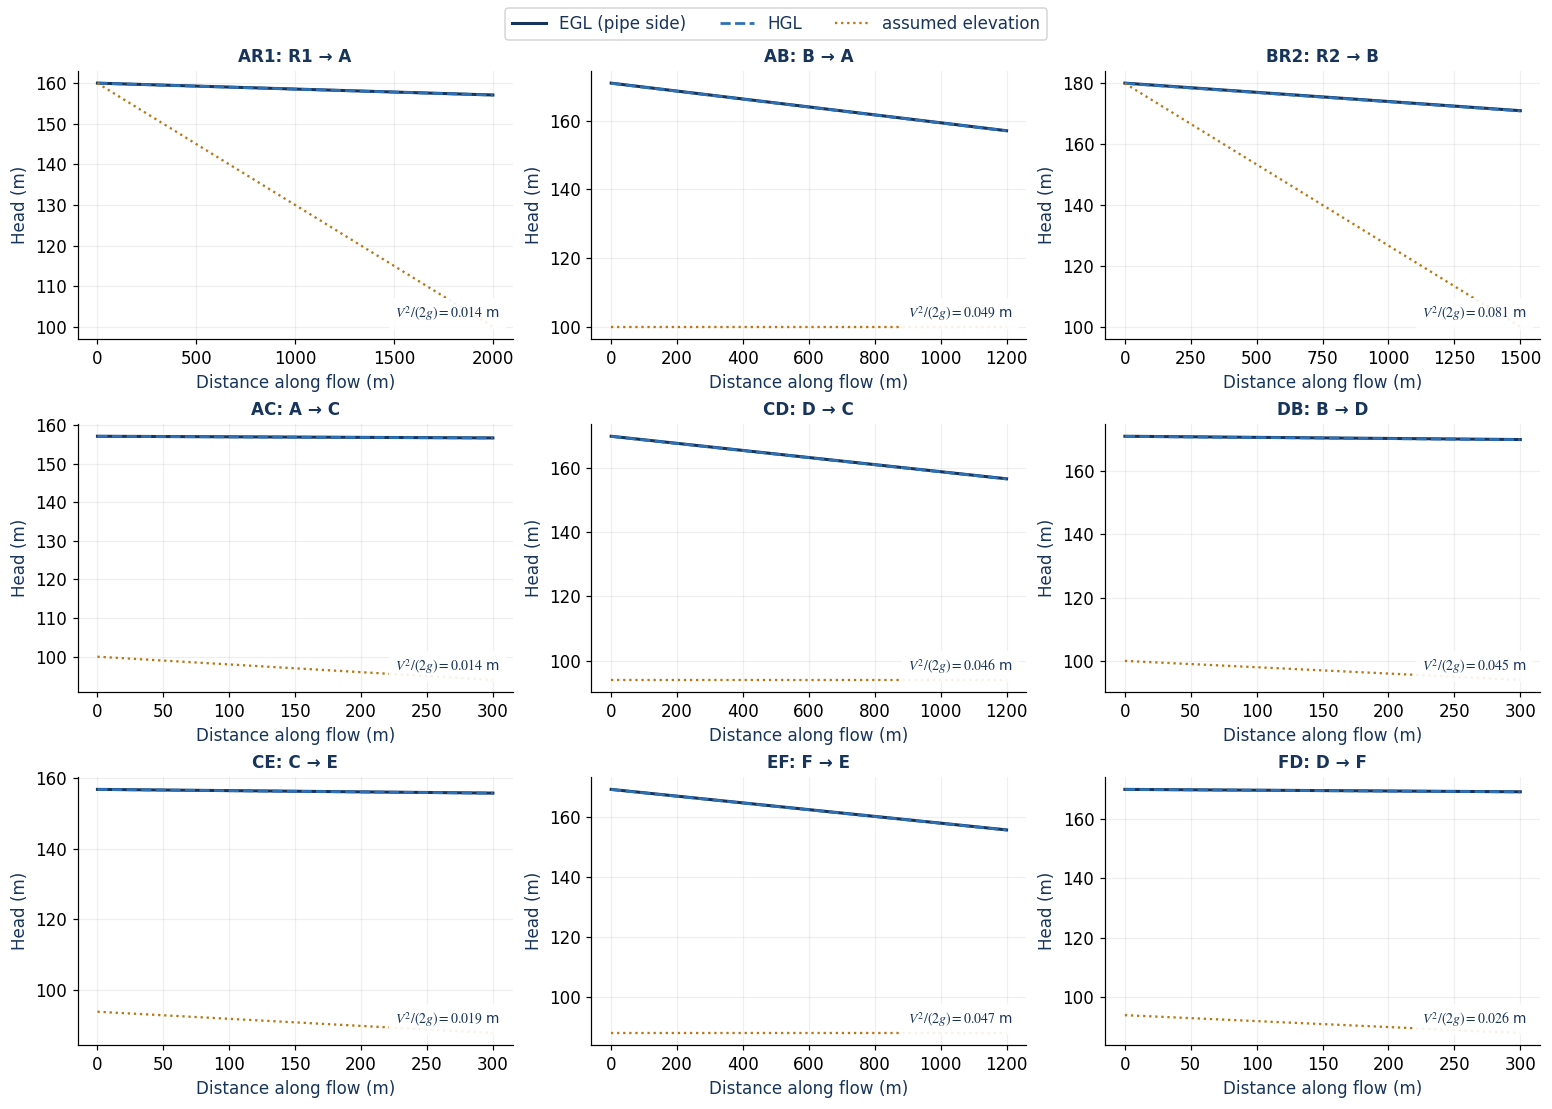

,z_m,HGL_m,pressure_head_m,gauge_pressure_kPa
A,100,157.0784,57.0784,558.9307
B,100,170.9435,70.9435,694.7029
C,94,156.6473,62.6473,613.4639
D,94,169.9061,75.9061,743.2985
E,88,155.6020,67.6020,661.9821
F,88,169.0980,81.0980,794.1390


09:38:27 | INFO    | Plotted pipe-side EGL/HGL. Local transition and reservoir-entry details are outside the Lab 5 friction-only model.


In [9]:
step(log, 9, 'Plot all nine pipe grade profiles and list junction pressures')
fig = plot_profiles5(solution); display(fig); plt.close(fig)
display(solution['nodes'][['z_m','HGL_m','pressure_head_m','gauge_pressure_kPa']].round(4))
log.info('Plotted pipe-side EGL/HGL. Local transition and reservoir-entry details are outside the Lab 5 friction-only model.')


### 9a. Interactive pipe detail: make the HGL–EGL gap visible

The elevation scale can be tens of metres, while velocity head may be only a few centimetres. Nearly overlapping curves do not imply zero velocity head. This explorer keeps the numerical axes honest: one panel shows HGL and EGL, a second isolates their actual difference, and a third shows pressure head relative to the local pipe elevation.

Select any pipe below. The explorer uses the **baseline solved case**; it does not change inputs or rerun the solver. The static example is retained so this explanation is readable on GitHub. In the pressure panel, the reservoir endpoint is a plotting reference rather than a resolved entrance section, as explained above.


09:38:27 | INFO    | STEP 9a | Inspect a single pipe and its velocity-head difference


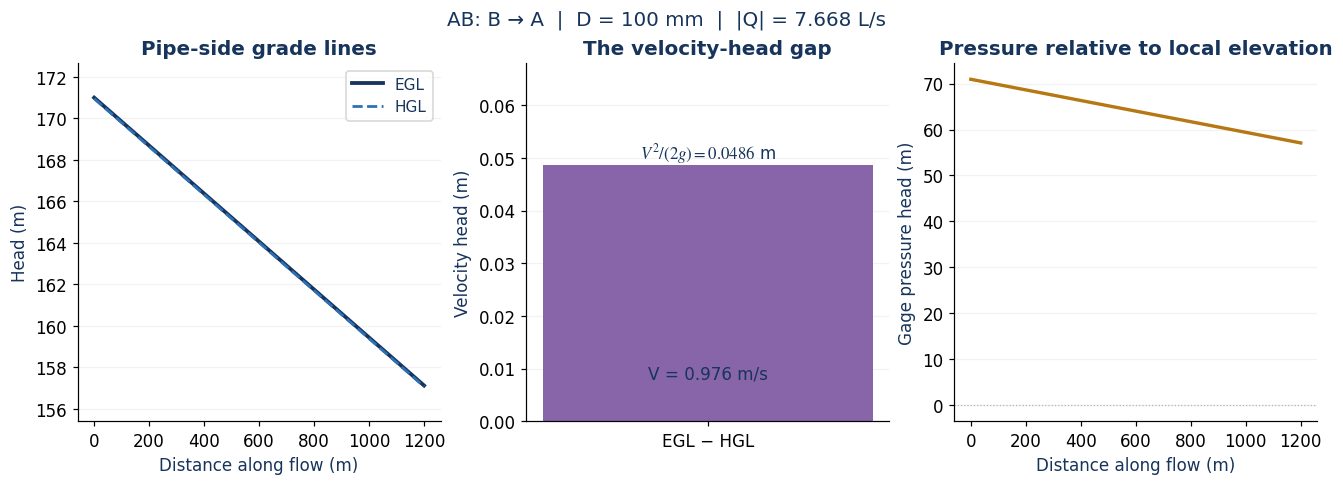

Interactive controls: run this cell in JupyterLab or Binder to activate.

09:38:27 | INFO    | Pipe explorer ready: choose a pipe to inspect the baseline without changing the calculation.


In [10]:
step(log, '9a', 'Inspect a single pipe and its velocity-head difference')
fig = plot_pipe_detail5(solution, 'AB'); display(fig); plt.close(fig)
from lab_widgets import PipeExplorer5
pipe_explorer = PipeExplorer5(solution)
display(pipe_explorer.widget)
log.info('Pipe explorer ready: choose a pipe to inspect the baseline without changing the calculation.')


## 10. Screen the preliminary design — do not call it optimal

The next cell compares solved velocities with your initial 1 m/s target. It also applies an **illustrative** minimum junction pressure head of 15 m and maximum pipe speed of 2 m/s. These are editable teaching thresholds, **not requirements stated by the manual or a design standard**. The manual supplies no cost data or allowable maximum pressure; the screen cannot establish a final or least-cost municipal design.

High pressure can also matter even when minimum pressure passes. Report the full pressure range and consider what additional pressure-rating or pressure-control information a real design would need. A prescribed-demand solution with negative pressure is not physically credible merely because its residual is small.


In [11]:
step(log, 10, 'Evaluate explicit teaching criteria')
# YOUR INPUT: disclose these choices; they are not supplied by the manual.
MIN_PRESSURE_HEAD_M = 15.0
MAX_SPEED_M_S = 2.0
screen = solution['pipes'][['D_mm','V_m_s']].copy()
screen['speed_minus_target_m_s'] = screen.V_m_s-TARGET_SPEED_M_S
screen['below_selected_speed_limit'] = screen.V_m_s <= MAX_SPEED_M_S
display(screen)
pressure_ok = solution['nodes'].pressure_head_m.min() >= MIN_PRESSURE_HEAD_M
log.info('Minimum node pressure head %.3f m; maximum %.3f m. Selected minimum criterion passes: %s.',
         solution['nodes'].pressure_head_m.min(),solution['nodes'].pressure_head_m.max(),pressure_ok)
log.info('Maximum pipe speed %.3f m/s; selected limit %.3f m/s. No cost or maximum-pressure optimization has been performed.',
         solution['pipes'].V_m_s.max(),MAX_SPEED_M_S)


09:38:27 | INFO    | STEP 10 | Evaluate explicit teaching criteria


,D_mm,V_m_s,speed_minus_target_m_s,below_selected_speed_limit
pipe,,,,
AR1,200.0,0.51981,-0.48019,True
AB,100.0,0.97626,-0.02374,True
BR2,250.0,1.25836,0.25836,True
AC,200.0,0.51528,-0.48472,True
CD,100.0,0.95383,-0.04617,True
DB,250.0,0.94306,-0.05694,True
CE,125.0,0.60376,-0.39624,True
EF,100.0,0.96266,-0.03734,True
FD,200.0,0.71718,-0.28282,True


09:38:27 | INFO    | Minimum node pressure head 57.078 m; maximum 81.098 m. Selected minimum criterion passes: True.


09:38:27 | INFO    | Maximum pipe speed 1.258 m/s; selected limit 2.000 m/s. No cost or maximum-pressure optimization has been performed.


## 11. Controlled experiment A — same pipes, different demands

Run both interpretations from §2 **without resizing the pipes**. This isolates the effect of demand. The population case keeps the relative allocation among nodes but changes its total. The loop structure and reservoir heads remain the same.

Predict how each reservoir’s contribution will change. A reservoir’s supply fraction need not remain constant when total demand changes; the 20 m head difference can drive transfer between reservoirs as well as customer supply.


In [12]:
step(log, '11A', 'Compare demand cases using identical diameters')
demand_runs = {}
summary = []
for mode in ['table','population']:
    case = copy.deepcopy(config)
    case['demand'] = lab5_config(mode)['demand']
    case['demand_mode'] = mode
    log.info('Demand scenario: %s', mode)
    result = hardy_cross5(case, log=log)
    demand_runs[mode] = result
    summary.append({'mode':mode,'total_demand_L_s':sum(case['demand'].values())*1000,
                    'R1_supply_L_s':result['supplies']['R1']*1000,'R2_supply_L_s':result['supplies']['R2']*1000,
                    'minimum_pressure_head_m':result['nodes'].pressure_head_m.min(),
                    'maximum_speed_m_s':result['pipes'].V_m_s.max()})
demand_summary = pd.DataFrame(summary).set_index('mode')
display(demand_summary.round(5))


09:38:27 | INFO    | STEP 11A | Compare demand cases using identical diameters


09:38:27 | INFO    | Demand scenario: table


09:38:27 | INFO    | Sweep 001 | max energy residual 2.104e+01 m | largest correction 1.016e+01 L/s | mass 4.86e-17 m3/s


09:38:27 | INFO    | Sweep 002 | max energy residual 2.418e+01 m | largest correction 5.334e+00 L/s | mass 4.86e-17 m3/s


09:38:27 | INFO    | Sweep 003 | max energy residual 1.346e+01 m | largest correction 4.257e+00 L/s | mass 4.51e-17 m3/s


...

09:38:28 | INFO    | Sweep 063 | max energy residual 7.298e-09 m | largest correction 1.470e-09 L/s | mass 2.08e-17 m3/s


09:38:28 | INFO    | CONVERGED | pipe energy 2.14e-09 m; node continuity 2.08e-17 m3/s; total demand 52.0833 L/s


09:38:28 | INFO    | R1: supplies 3.0677 L/s


09:38:28 | INFO    | R2: supplies 49.0156 L/s


,total_demand_L_s,R1_supply_L_s,R2_supply_L_s,minimum_pressure_head_m,maximum_speed_m_s
mode,,,,,
table,78.10000,16.33034,61.76966,57.07835,1.25836
population,52.08333,3.06773,49.01560,59.86582,0.99854


## 12. Controlled experiment B — compare two diameter choices

Choose one pipe to enlarge, keeping demands, roughness, reservoir heads, and all other diameters fixed. The default experiment enlarges AB by 50 mm. Predict both the local change and the network redistribution before running. A larger AB does not guarantee that every pipe’s flow or every junction pressure changes in the same direction.

This is a comparison, not an optimizer. Use the editable design bench next if you want to test several sizes. Keep a record of the exact inputs for every design you discuss.


In [13]:
step(log, '12B', 'Change one diameter and compare the whole network')
PIPE_TO_CHANGE = 'AB'
DIAMETER_INCREASE_MM = 50.0
alternative_config = copy.deepcopy(config)
alternative_config['pipes'].loc[PIPE_TO_CHANGE,'D_m'] += DIAMETER_INCREASE_MM/1000
alternative = hardy_cross5(alternative_config, log=log)
design_compare = pd.DataFrame({'baseline_Q_L_s':solution['pipes'].Q_L_s,
                               'alternative_Q_L_s':alternative['pipes'].Q_L_s,
                               'baseline_speed_m_s':solution['pipes'].V_m_s,
                               'alternative_speed_m_s':alternative['pipes'].V_m_s})
design_compare['flow_change_L_s'] = design_compare.alternative_Q_L_s-design_compare.baseline_Q_L_s
display(design_compare.round(5))
display(pd.DataFrame({'baseline_pressure_head_m':solution['nodes'].pressure_head_m,
                      'alternative_pressure_head_m':alternative['nodes'].pressure_head_m}).round(5))
log.info('Changed only %s diameter by %+.1f mm. Explain the redistribution before choosing a design.', PIPE_TO_CHANGE, DIAMETER_INCREASE_MM)


09:38:28 | INFO    | STEP 12B | Change one diameter and compare the whole network


09:38:28 | INFO    | Sweep 001 | max energy residual 2.420e+01 m | largest correction 3.019e+01 L/s | mass 4.86e-17 m3/s


09:38:28 | INFO    | Sweep 002 | max energy residual 2.749e+00 m | largest correction 9.575e+00 L/s | mass 4.51e-17 m3/s


09:38:28 | INFO    | Sweep 003 | max energy residual 1.378e+00 m | largest correction 7.684e-01 L/s | mass 4.51e-17 m3/s


09:38:28 | INFO    | Sweep 004 | max energy residual 6.789e-01 m | largest correction 3.687e-01 L/s | mass 4.51e-17 m3/s


...

09:38:28 | INFO    | R1: supplies 8.2987 L/s


09:38:28 | INFO    | R2: supplies 69.8013 L/s


,baseline_Q_L_s,alternative_Q_L_s,baseline_speed_m_s,alternative_speed_m_s,flow_change_L_s
pipe,,,,,
AR1,-16.33034,-8.29871,0.51981,0.26416,8.03163
AB,-7.66753,-18.28776,0.97626,1.03488,-10.62023
BR2,-61.76966,-69.80129,1.25836,1.42198,-8.03163
AC,16.18787,18.77647,0.51528,0.59767,2.58860
CD,-7.49139,-6.11506,0.95383,0.77859,1.37633
DB,-46.29213,-43.70353,0.94306,0.89032,2.58860
CE,7.40926,8.62153,0.60376,0.70255,1.21227
EF,-7.56074,-6.34847,0.96266,0.80831,1.21227
FD,-22.53074,-21.31847,0.71718,0.67859,1.21227


,baseline_pressure_head_m,alternative_pressure_head_m
A,57.07835,59.17712
B,70.94349,68.51759
C,62.64731,64.60609
D,75.90610,73.58892
E,67.60202,69.21143
F,81.09796,78.86175


09:38:28 | INFO    | Changed only AB diameter by +50.0 mm. Explain the redistribution before choosing a design.


**Your comparison:**

Which diameter choice do you prefer under your stated criteria? Give numerical evidence, discuss pressure as well as velocity, and identify what information is missing for a real cost or feasibility decision.


## 13. Interactive design bench

Edit all nine diameters directly in mm. Choose the demand interpretation, multiply that demand by a stated factor, or vary roughness in mm. Click **Run Hardy–Cross** to view the log, pipe results, node pressures, actual arrows, and convergence history.

Inputs do not automatically resize the pipes, so demand sensitivity is not mixed with redesign. Any edit disables Save and marks the previous result stale. The latest successful panel result is `design_bench.last_result`; `solution` remains your code-cell baseline. If controls are unavailable, the configuration and experiment cells provide the same calculations.


In [14]:
step(log, 13, 'Open the interactive design bench')
from lab_widgets import Lab5Workbench
design_bench = Lab5Workbench(config, log)
display(design_bench.widget)
log.info('Design bench ready. A changed input requires a new run before export.')


09:38:28 | INFO    | STEP 13 | Open the interactive design bench


Interactive controls: run this cell in JupyterLab or Binder to activate.

09:38:28 | INFO    | Design bench ready. A changed input requires a new run before export.


## 14. Report and discussion prompts

Follow the course lab-report format. Your submission should explain a design, not merely print tables.

1. Show the topology, reference directions, source data, selected demand interpretation, and diameter choices. Explain the roughness conversion.
2. Give one continuity-balanced initial flow set and show the six node checks. Explain how it was chosen.
3. Work one complete Hardy–Cross correction by hand, including the shared pipe’s sign. Explain the difference between frozen-f and variable-f corrections.
4. Include the third reservoir-path equation and explain what would be undetermined if you omitted it.
5. Present final flows, reservoir supplies, node heads, f and Re, and both conservation and independent-solver checks.
6. Provide HGL/EGL profiles with the friction-dominated model limitations clearly stated.
7. Compare the demand scenarios and two diameter choices. State your criteria and distinguish preliminary sizing from optimization.
8. The manual requests hand and Bentley calculations. This notebook supplies an open-source computational counterpart. If your instructor also requires Bentley output, reproduce the same node/pipe tables, Darcy–Weisbach method, roughness, demands, and fixed heads there; compare differences without claiming a Bentley run you did not perform.

**Answer here:** Why can two designs both satisfy continuity and energy but differ in suitability? How would pressure-dependent demand alter your interpretation of a negative-pressure result? What extra data would you request before finalizing pipe sizes?


## 15. Export, download, and reproduce
The baseline ZIP contains configuration, flows, node pressures, full iteration history, profiles, checks, and figures. Additional comparison CSVs are linked separately. Workbench scenarios use a separate ZIP name. Download the edited notebook too, then restart and run it once to confirm your reported design is reproducible.


In [15]:
step(log, 15, 'Export the design calculation and comparison tables')
figures = {'network':network_plot5(solution),'convergence':plot_history5(solution),'grade_profiles':plot_profiles5(solution),'AB_detail':plot_pipe_detail5(solution,'AB')}
archive = export_result(solution, 'lab5_baseline', figures)
for fig in figures.values(): plt.close(fig)
demand_summary.to_csv('outputs/lab5_demand_comparison.csv')
design_compare.to_csv('outputs/lab5_diameter_comparison.csv')
log.info('Export complete: %s. Download it and your edited notebook before closing Binder.', archive)
display(DownloadLink(str(archive)))
display(DownloadLink('outputs/lab5_demand_comparison.csv'))
display(DownloadLink('outputs/lab5_diameter_comparison.csv'))


09:38:28 | INFO    | STEP 15 | Export the design calculation and comparison tables


09:38:30 | INFO    | Export complete: outputs/lab5_baseline.zip. Download it and your edited notebook before closing Binder.


outputs/lab5_baseline.zip

outputs/lab5_demand_comparison.csv

outputs/lab5_diameter_comparison.csv

## Troubleshooting and final self-check

| Symptom | What to check |
|---|---|
| Initial continuity check fails | Pipe signs or units are wrong. Use the seed construction or repair node balances before looping. |
| Two loops close but reservoir split looks arbitrary | Include the R1–R2 path and its −20 m target. |
| Negative pipe flow | Read the reference direction; speed uses its magnitude. |
| Convergence is slow | Inspect all three residuals, friction regime, extreme diameters, and units. Do not increase the iteration limit without diagnosing the model. |
| Results change after a restart | Cells were executed out of order or stale variables were used. Restart and Run All with the intended inputs. |
| f is undefined at exactly zero flow | The code uses zero head loss and a finite laminar slope; an undefined tabular f at Q = 0 is intentional. |
| Very large or negative node pressure | Check boundary heads and diameters, then distinguish mathematical convergence from a feasible water-supply design. |
| Different answer from a classmate | Compare demand interpretation, all diameters, roughness, viscosity, and head references first. |

Before submitting, verify that your reported inputs, tables, plots, logs, and written interpretation all belong to the same design run.


### Reproduce an exported case

Extract your downloaded ZIP. Its `inputs.json` stores all model inputs, while `manifest.json` lists the files from that export. The session log can include several runs; use the JSON inputs and associated tables to identify the case you report. You can reload those inputs in this same repository:

```python
restored = load_saved_inputs('outputs/CASE_NAME/inputs.json')
```

Replace `CASE_NAME` with your exported folder name. For Lab 4, run `solve4(restored, log)`; for Lab 5, run `hardy_cross5(restored, log=log)`. The configuration restores pipe labels, units, and all saved scenario choices. Compare the recomputed flows and conservation residuals with the exported tables. An old ZIP does not automatically track later changes to notebook inputs; export again after each accepted run.


## References

Colebrook, C. F. (1939). Turbulent flow in pipes, with particular reference to the transition region between the smooth and rough pipe laws. *Journal of the Institution of Civil Engineers, 11*(4), 133–156. https://doi.org/10.1680/ijoti.1939.13150

Cross, H. (1936). *Analysis of flow in networks of conduits or conductors* (Engineering Experiment Station Bulletin No. 286). University of Illinois. https://hdl.handle.net/2142/4433

Swamee, P. K., & Jain, A. K. (1976). Explicit equations for pipe-flow problems. *Journal of the Hydraulics Division, 102*(5), 657–664. https://doi.org/10.1061/JYCEAJ.0004542

These references support the pipe-friction equations and network-balancing methods. The assigned network dimensions, demand cases, and explicitly labelled teaching assumptions are the inputs to this laboratory exercise; they are not attributed to these papers.

The teaching solver covers steady, incompressible, full-pipe models. It does not resolve transients, air pockets, pipe collapse, or three-dimensional fitting flow. A small residual confirms the stated equations were solved, not that every physical process was represented.
